# Two endpoints and selectivity

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/04_two_endpoints.ipynb)

When the same molecules are measured against two targets, the two activities can be fitted
together on one kernel, tied by a correlation between the endpoints. A molecule measured against
one target then informs the prediction for the other, and the difference of the two endpoints,
the selectivity, becomes a model of its own instead of a ratio of two noisy numbers. The manual
explains this in *Several endpoints at once: the selectivity co-field*.

The data (`examples/cyclodextrin/beta_with_alpha.csv`) are 1162 guests with their association
constant to beta-cyclodextrin, 496 of which also carry the constant to alpha-cyclodextrin. The
kernel is the rotation-invariant one of the second notebook, since the guests share no frame.

Running time: about two minutes, most of it building 3D structures.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


In [2]:
import numpy as np
from cmfqsar import load_dataset, FieldSet, CMFModel
from cmfqsar.fields import AtomTable, build_fields
from cmfqsar import multitask as MT

ds = load_dataset("examples/cyclodextrin/beta_with_alpha.csv", activity_prop="activity")
alpha = np.array([float(m.GetProp("alpha_logK")) if m.HasProp("alpha_logK") and
                  m.GetProp("alpha_logK").strip() else np.nan for m in ds.mols])
fs = FieldSet.create(alpha=1.0)
mf = [build_fields(m, fs, n) for m, n in zip(ds.mols, ds.names)]
model = CMFModel(fieldset=fs, method="krr", normalize=True, kernel_source="autocorrelation")
K = model.training_kernel(AtomTable.from_molecules(mf))
obs = MT.Observations.from_columns(np.column_stack([ds.activity, alpha]), names=("beta", "alpha"))
print(len(ds), "guests;", obs.counts(), "measurements per endpoint")

[01:01:35] UFFTYPER: Unrecognized charge state for atom: 4


[01:01:59] UFFTYPER: Warning: hybridization set to SP3 for atom 1
[01:01:59] UFFTYPER: Unrecognized charge state for atom: 1


[01:02:14] UFFTYPER: Unrecognized charge state for atom: 4


1162 guests; [1162, 496] measurements per endpoint


## How much does sharing help?

`rho` is the correlation between the endpoints: 0 fits them separately on the same kernel, values
near 1 force their coefficients together. The cross-validation holds out whole molecules, so a
guest's beta value never helps predict its own alpha value.

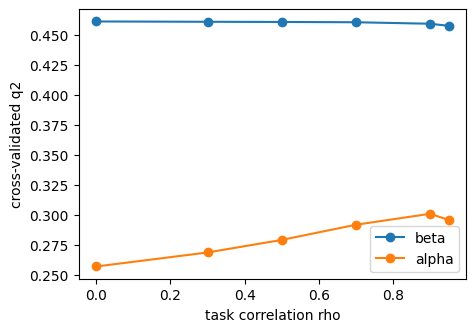

beta   q2 alone 0.461, best with sharing 0.461 at rho = 0.00
alpha  q2 alone 0.257, best with sharing 0.301 at rho = 0.90


In [3]:
import matplotlib.pyplot as plt

lam = 0.01
rhos = [0.0, 0.3, 0.5, 0.7, 0.9, 0.95]
scores = {name: [] for name in obs.task_names}
for rho in rhos:
    for t in MT.score_by_task(obs, MT.cv_predict(K, obs, rho=rho, lam=lam, folds=10)):
        scores[t["task"]].append(t["q2"])
fig, ax = plt.subplots(figsize=(5, 3.5))
for name, q in scores.items():
    ax.plot(rhos, q, "o-", label=name)
ax.set_xlabel("task correlation rho"); ax.set_ylabel("cross-validated q2"); ax.legend(); plt.show()
for name, q in scores.items():
    print("%-6s q2 alone %.3f, best with sharing %.3f at rho = %.2f" % (name, q[0], max(q), rhos[int(np.argmax(q))]))

The endpoint with fewer measurements gains more: it borrows what the two have in common from
the better-measured one. `MT.search` chooses `rho` and `lambda` by the same cross-validation,
and `MT.evidence_rho` chooses `rho` by the marginal likelihood without holding anything out.

In [4]:
rho, lam, score, per_task = MT.search(K, obs, rhos=[0.0, 0.5, 0.9], lams=[0.01, 0.1, 1.0])
print("chosen rho = %.2f, lambda = %g, mean q2 = %.3f" % (rho, lam, score))
fit = MT.fit(K, obs, rho=rho, lam=lam)

chosen rho = 0.90, lambda = 0.01, mean q2 = 0.380


## Selectivity

The difference of the two endpoints is itself a linear model on the kernel, with coefficients
that are the difference of the two sets. Its cross-validated q2, on the guests measured against
both hosts, says how well the *preference* for one cavity over the other is predicted.

In [5]:
sel = MT.score_selectivity(K, obs, 0, 1, rho=rho, lam=lam, folds=10)
print("selectivity (beta - alpha) on %d guests measured against both: q2 = %.3f, RMSE = %.3f"
      % (sel["n"], sel["q2"], sel["rmse_cv"]))

pred_sel = fit.predict_selectivity(K, 0, 1)
both = np.isfinite(ds.activity) & np.isfinite(alpha)
order = np.argsort(-pred_sel)
print("\nguests predicted to prefer beta-cyclodextrin most strongly:")
for i in order[:8]:
    measured = "%.2f" % (ds.activity[i] - alpha[i]) if both[i] else "not measured against alpha"
    print("  %-40s predicted %.2f   measured %s" % (ds.names[i][:40], pred_sel[i], measured))

selectivity (beta - alpha) on 496 guests measured against both: q2 = 0.306, RMSE = 0.708

guests predicted to prefer beta-cyclodextrin most strongly:
  perfluorooctanoic acid                   predicted 2.07   measured 2.89
  bencyclane [CID86308591]                 predicted 2.01   measured not measured against alpha
  perfluorononanoic acid                   predicted 2.00   measured 2.50
  O=C(O)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F predicted 1.95   measured 2.48
  bdbm36263                                predicted 1.91   measured not measured against alpha
  camphor                                  predicted 1.91   measured 1.28
  bdbm36264                                predicted 1.91   measured not measured against alpha
  CC(C)C12CCC(C)(CC1)N=N2                  predicted 1.90   measured not measured against alpha


## The same model from the command line

```
cmf build examples/cyclodextrin/beta_with_alpha.csv --kernel autocorrelation --second-endpoint alpha_logK --save beta_alpha.cmf
```

With an aligned series and the overlap kernel, `cmf cofield --endpoint selectivity` writes the
selectivity co-field: the map of where a field makes a molecule prefer one target over the other.
The manual's chapter *Several endpoints at once* shows it on a two-target series.